# Historical research notebook
Original calculations and saved outputs are retained. See [experiment notes](../../docs/EXPERIMENT_NOTES.md) before interpreting results.


In [ ]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "VB_FTRL.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Start Jupyter from within the repository")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))


Rows (trading days): 3,774
Total assets:        501
Completely clean columns: 427
<5 % missing columns:     427


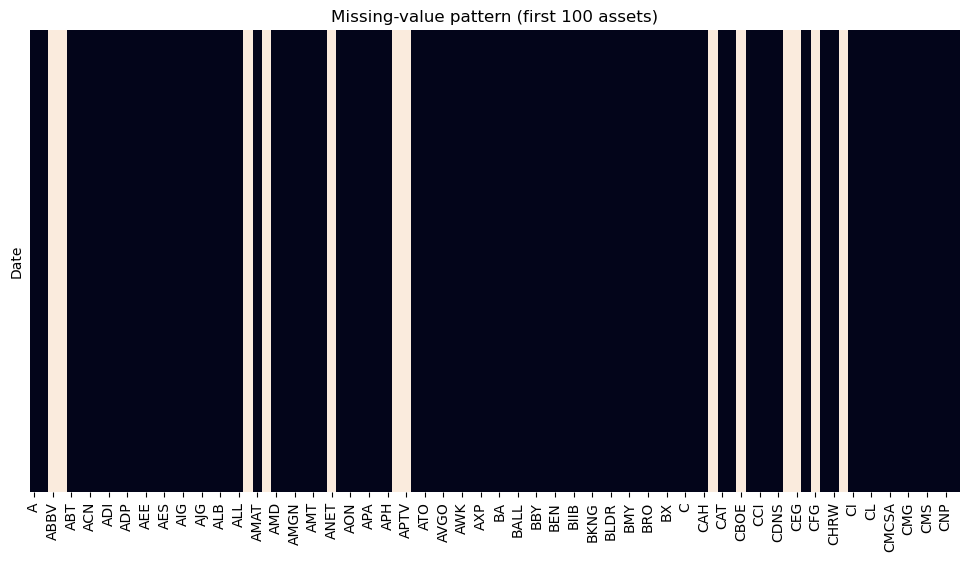

In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1) Load
df = pd.read_csv(str(ROOT / "data" / "SP500_normalized_prices.csv.xz"))
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date")

# 2) Quick stats
n_rows, n_cols = df.shape
missing_pct = df.isna().mean()          # % NaNs per column
complete_cols = missing_pct[missing_pct == 0].index
almost_complete = missing_pct[missing_pct < 0.05].index  # <5 % NaNs

print(f"Rows (trading days): {n_rows:,}")
print(f"Total assets:        {n_cols:,}")
print(f"Completely clean columns: {len(complete_cols)}")
print(f"<5 % missing columns:     {len(almost_complete)}")

# 3) Visual snapshot of missingness (optional but useful)
plt.figure(figsize=(12, 6))
sns.heatmap(df.iloc[:, :100].isna(), cbar=False, yticklabels=False)
plt.title("Missing-value pattern (first 100 assets)")
plt.show()


In [64]:
import numpy as np
import pandas as pd

# -- settings --------------------------------------------------------------
N_RUNS      = 10          # number of experiments
d           = 10         # assets per experiment
RNG_SEED    = 42          # for reproducibility
PRICE_FILE  = str(ROOT / "data" / "SP500_normalized_prices.csv.xz")

# -- load & keep only clean columns ----------------------------------------
df = pd.read_csv(PRICE_FILE, parse_dates=["Date"]).set_index("Date")
clean_cols = df.columns[df.notna().all()]   # 427 tickers

print(f"Using {len(clean_cols)} assets with complete data.")

# -- draw panels and build price-relative matrices -------------------------
rng        = np.random.default_rng(RNG_SEED)
panels     = []           # list of ticker lists
X_matrices = []           # list of (d,T) numpy arrays

for run in range(N_RUNS):
    tickers = rng.choice(clean_cols, size=d, replace=False)
    panels.append(list(tickers))

    prices  = df[tickers].to_numpy().T          # shape (d,T)
    X       = prices[:, 1:] / prices[:, :-1]    # price relatives
    X_matrices.append(X)

    print(f"Run {run:2d}: {', '.join(tickers)}   (matrix {X.shape})")


Using 427 assets with complete data.
Run  0: AVB, PWR, AVGO, MTD, HES, HBAN, ORCL, AXON, CNP, TAP   (matrix (10, 3773))
Run  1: RJF, GL, FDS, MTB, SPG, CINF, HPQ, IVZ, LII, UNH   (matrix (10, 3773))
Run  2: ON, PPG, DLR, HRL, EXPD, CCI, MOH, TSN, WFC, ANSS   (matrix (10, 3773))
Run  3: WEC, GOOGL, PNC, EQIX, NTAP, PKG, FDS, TYL, CAG, UDR   (matrix (10, 3773))
Run  4: PARA, STE, CRM, NI, V, MS, HES, CBRE, LNT, EQIX   (matrix (10, 3773))
Run  5: NTAP, DRI, ACGL, CNC, CTRA, BR, MS, SRE, SBAC, SCHW   (matrix (10, 3773))
Run  6: CVX, NRG, LOW, AIZ, HOLX, BR, INTC, JBHT, BDX, NEE   (matrix (10, 3773))
Run  7: EVRG, MDT, EBAY, WSM, DOV, ROK, LIN, HIG, CPB, AFL   (matrix (10, 3773))
Run  8: ROK, HBAN, NOC, JKHY, TTWO, DVA, LLY, YUM, NEE, BKNG   (matrix (10, 3773))
Run  9: CBRE, TT, JCI, VRSN, AVGO, PEG, OKE, XEL, HUM, PTC   (matrix (10, 3773))


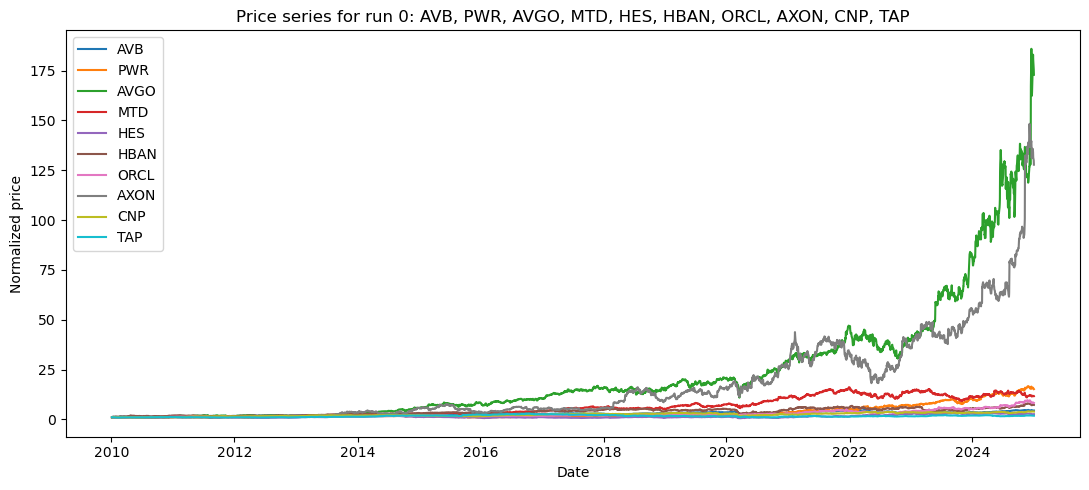

In [65]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you've run the previous cell and have `df` (price DataFrame) and `panels`
run = 0  # which experiment to visualise
tickers = panels[run]

plt.figure(figsize=(11, 5))
for ticker in tickers:
    plt.plot(df.index, df[ticker], label=ticker)

plt.title(f"Price series for run {run}: " + ", ".join(tickers))
plt.xlabel("Date")
plt.ylabel("Normalized price")
plt.legend()
plt.tight_layout()
plt.show()


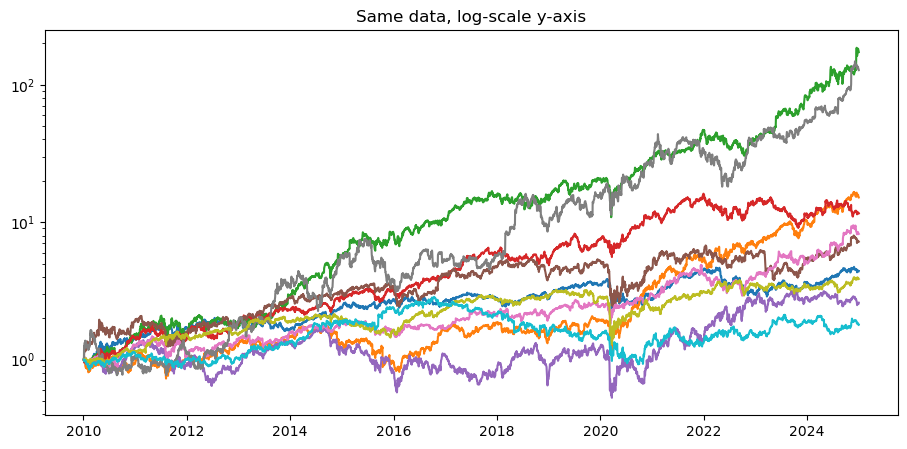

In [66]:
plt.figure(figsize=(11,5))
for ticker in tickers:
    plt.plot(df.index, df[ticker], label=ticker)
plt.yscale("log")
plt.title("Same data, log-scale y-axis")
plt.show()


In [67]:
def run_universal_portfolio(X, grid, lam=10.0):
    """
    Discrete Cover 1991 algorithm.
    X    : (d, T) price-relatives
    grid : (K, d) lattice of CRP weights
    lam  : inverse-temperature (λ). 10 is standard.
    Returns
        S  : length-T wealth vector
        W  : (T, d) allocation history  (optional for inspection)
    """
    d, T = X.shape
    K    = grid.shape[0]

    S  = np.ones(T)
    W  = np.empty((T, d))
    log_u = np.zeros(K)              # log utility of each CRP
    w_t = np.full(d, 1/d)            # start  equal-weighted

    for t in range(T):
        # realise return
        S[t] = S[t-1] * (w_t @ X[:, t]) if t else 1.0

        # update utilities
        log_u += np.log(grid @ X[:, t])

        # log-sum-exp trick
        a      = lam * log_u
        a_max  = np.max(a)
        post   = np.exp(a - a_max)
        post  /= post.sum()          # posterior mass on each CRP

        w_t    = post @ grid         # Cover’s mixture allocation
        W[t]   = w_t

    return S, W


In [68]:
import numpy as np
from itertools import combinations

def simplex_lattice(d, delta=0.1):
    """
    Fast version: directly generate the (K, d) simplex lattice points.
    Avoids brute-force product + filtering.
    """
    n = int(round(1 / delta))
    points = []

    # Generate all combinations of (n + d - 1) choose (d - 1)
    for c in combinations(range(n + d), d - 1):
        dividers = (0,) + c + (n + d,)
        p = np.diff(dividers) - 1  # subtract 1 for offset
        points.append(p / n)

    return np.array(points, dtype=float)


In [69]:
import importlib            # built-in
import VB_FTRL             # first import – runs the file once
importlib.reload(VB_FTRL)   # use this cell again whenever you modify the .py file
from VB_FTRL import VB_FTRL                 # the class itself

# If you **added** the wrapper inside the .py file, grab it too:
# from VB_FTRL import run_vb_ftrl_qn

# -------------------------------------------------------------------------
# Wrapper: run_vb_ftrl_qn
# -------------------------------------------------------------------------
def run_vb_ftrl_qn(X, *, mu=6, lambda_val=7, S=10):
    """
    Vectorised Buyback FTRL (quasi-Newton) wrapper.

    Parameters
    ----------
    X : (d, T) ndarray
        Price-relatives matrix.
    mu, lambda_val, S : hyper-parameters copied from the VB_FTRL constructor.

    Returns
    -------
    S_vec : (T,) ndarray
        Wealth path (start at 1).
    W_hist : (T, d) ndarray
        Allocation history.
    """
    d, T  = X.shape
    algo  = VB_FTRL(d, mu=mu, lambda_val=lambda_val, S=S)

    S_vec = np.ones(T)
    W_hist = np.empty((T, d))

    for t in range(T):
        # --- realise return ---------------------------------------------
        if t > 0:
            S_vec[t] = S_vec[t-1] * (algo.w @ X[:, t])
        W_hist[t] = algo.w          # store pre-trade weight

        # --- feed new return vector -------------------------------------
        algo.update(X[:, t])

    return S_vec, W_hist


In [70]:
# ------------------------------------------------------------------
# keep only the last 750 columns (≈ 3 years) of every X matrix
# ------------------------------------------------------------------
T_SHORT     = 750
X_matrices_short = [X[:, -T_SHORT:] for X in X_matrices]

print(f"All panels now have shape {[X.shape for X in X_matrices_short][0]}")


All panels now have shape (10, 750)


In [93]:
X0 = X_matrices_short[0]          # run-0, 750-day slice

# UP (unchanged)
grid   = simplex_lattice(d, delta=0.075)
S_up, W_up = run_universal_portfolio(X0, grid, lam=20)

# VB-FTRL-qN – quicker now
S_vb, W_vb = run_vb_ftrl_qn(X0, mu=3, lambda_val=10**-5, S=10)   # S=5 is already fast

print(f"UP  final wealth: {S_up[-1]:.2f}")
print(f"VB final wealth:  {S_vb[-1]:.2f}")


UP  final wealth: 1.99
VB final wealth:  1.66


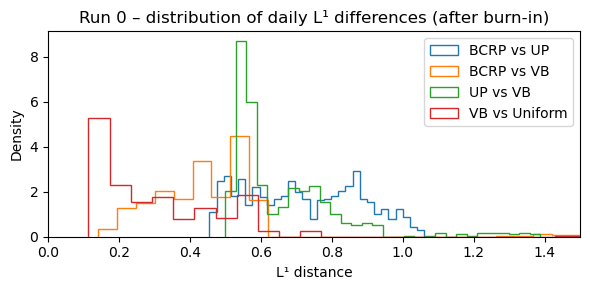

In [94]:
# ------------------------------------------------------------------
# L1-distance histograms – run 0 (after burn-in)
# ------------------------------------------------------------------
import numpy as np, matplotlib.pyplot as plt

# 1. BCRP weights for this slice  (already fixed by X0)
_, w_bcrp = wealth_bcrp(X0)           # shape (d,)

# 2. Helper
def l1(v1, v2):
    return np.abs(v1 - v2).sum()

burn_in = 75                          # skip the first 75 days

# 3. Distances
d_bcrp_up = [l1(w_bcrp, w)                 for w  in W_up[burn_in:]]        # BCRP ↔ UP
d_bcrp_vb = [l1(w_bcrp, w)                 for w  in W_vb[burn_in:]]        # BCRP ↔ VB   ← NEW
d_up_vb   = [l1(wu, wv)                    for wu, wv in zip(W_up[burn_in:], W_vb[burn_in:])]
d_vb_uni  = [l1(wv, np.full(d, 1/d))       for wv in W_vb[burn_in:]]

# 4. Histogram (outline style makes overlaps clear)
plt.figure(figsize=(6,3))
plt.hist(d_bcrp_up, bins=30, histtype="step", label="BCRP vs UP",     density=True)
plt.hist(d_bcrp_vb, bins=30, histtype="step", label="BCRP vs VB",     density=True)  # ← NEW
plt.hist(d_up_vb,   bins=30, histtype="step", label="UP vs VB",       density=True)
plt.hist(d_vb_uni,  bins=30, histtype="step", label="VB vs Uniform",  density=True)

plt.xlabel("L¹ distance"); plt.ylabel("Density")
plt.title("Run 0 – distribution of daily L¹ differences (after burn-in)")
plt.xlim(0, 1.5)            # lock x-axis so scales stay comparable
plt.legend(); plt.tight_layout()
plt.show()



In [97]:
w_bcrp

array([0.04877294, 0.14591647, 0.19373077, 0.03881918, 0.08587387,
       0.05746081, 0.10119317, 0.2016868 , 0.06296895, 0.06357706])

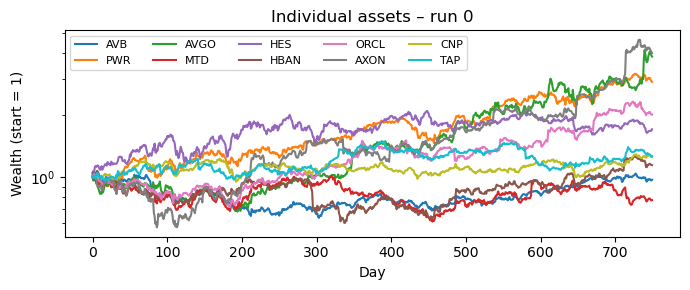

,UP_final_w,VB_final_w
ticker,,
AVB,-0.0665,0.0576
PWR,0.1082,0.0673
AVGO,0.3697,0.1686
MTD,0.0072,0.0421
HES,0.0347,0.0457
HBAN,0.0147,0.0443
ORCL,0.0426,0.0539
AXON,0.4548,0.4105
CNP,0.0167,0.0599



UP  final wealth: 1.99
VB  final wealth: 1.66


In [98]:
# ---------------------------------------------------------------
# 0. prerequisites
# ---------------------------------------------------------------
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. which assets are in run-0?
# ---------------------------------------------------------------
tickers0 = panels[0]           # assuming the same list you zipped earlier


# ---------------------------------------------------------------
# 2. buy-and-hold wealth curves for each asset
# ---------------------------------------------------------------
cum_prices = np.cumprod(X0, axis=1)          # (d, T)
plt.figure(figsize=(7,3))
for i, tkr in enumerate(tickers0):
    plt.plot(cum_prices[i], label=tkr)
plt.yscale("log")
plt.xlabel("Day"); plt.ylabel("Wealth (start = 1)")
plt.title("Individual assets – run 0")
plt.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 3. final allocations of each strategy
# ---------------------------------------------------------------
final_alloc = pd.DataFrame({
        "ticker": tickers0,
        "UP_final_w" : W_up[-1],
        "VB_final_w": W_vb[-1],
    }).set_index("ticker").round(4)

display(final_alloc)           # neat table in Jupyter

print("\nUP  final wealth:", f"{S_up[-1]:.2f}")
print("VB  final wealth:", f"{S_vb[-1]:.2f}")



Text(0.5, 1.0, 'max weight (UP)')

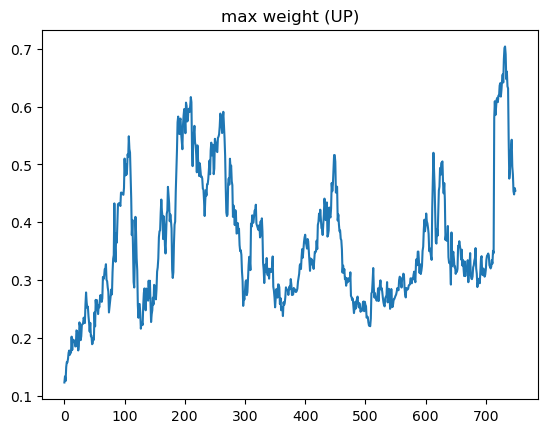

In [99]:
plt.plot(W_up.max(axis=1)); plt.title("max weight (UP)")



In [ ]:
UP_PARAMS = {"passive": (1,   0.075),
             "mild":    (10,  0.075),
             "aggr":    (25,  0.075)}

VB_PARAMS = {"passive": dict(mu=2,  lambda_val=1e-1,  S=10),
             "mild":    dict(mu=6,  lambda_val=1e-4,  S=10),
             "aggr":    dict(mu=12, lambda_val=1e-5,  S=10)}

results = []

for run, (tickers, X) in enumerate(zip(panels, X_matrices_short)):
    d = X.shape[0]                            # ← asset count for this slice

    for bucket in ["passive", "mild", "aggr"]:
        # ---- UP --------------------------------------------------------
        lam, delta = UP_PARAMS[bucket]
        grid       = simplex_lattice(d, delta)   # use local d, not global D
        S_up, W_up = run_universal_portfolio(X, grid, lam=lam)

        # ---- VB-FTRL-qN -------------------------------------------------
        S_vb, W_vb = run_vb_ftrl_qn(X, **VB_PARAMS[bucket])

        # ---- store ------------------------------------------------------
        results.append(dict(
            run     = run,
            bucket  = bucket,
            X       = X,              # keep a copy of the matrix
            S_up    = S_up,  W_up = W_up,
            S_vb    = S_vb,  W_vb = W_vb,
            w_uni   = np.full(d, 1/d)  # ← uniform weights, shape (d,)
        ))



In [ ]:
def wealth_uniform(X):
    d = X.shape[0]
    w = np.full(d, 1/d)
    return np.cumprod(w @ X)          #  axis defaults to 0 for 1-D input

def wealth_bcrp(X):
    g       = np.prod(X, axis=1)      # gross return per asset
    w_star  = g / g.sum()
    return np.cumprod(w_star @ X), w_star


In [ ]:


for rec in results:
   X = rec["X"]
   rec["S_uni"]  = wealth_uniform(X)
   rec["S_bcrp"], rec["w_bcrp"] = wealth_bcrp(X)
   d = X.shape[0] 
   rec["w_uni"]  = np.full(d, 1/d)   
    


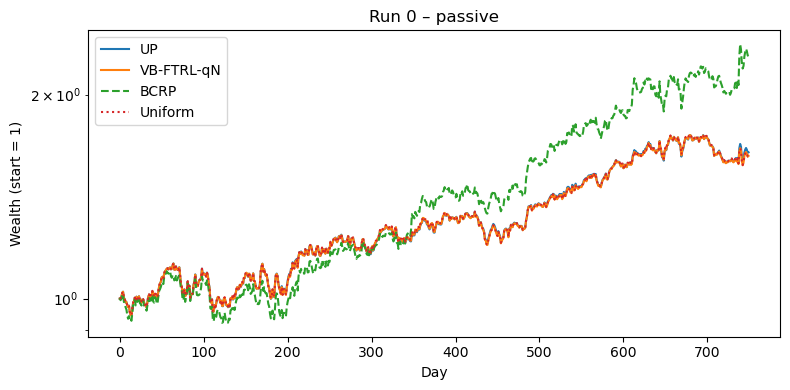

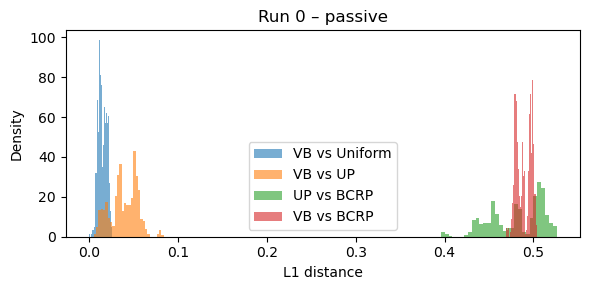

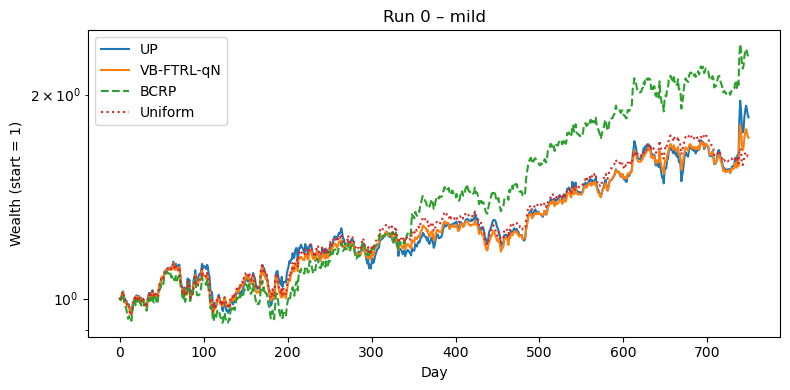

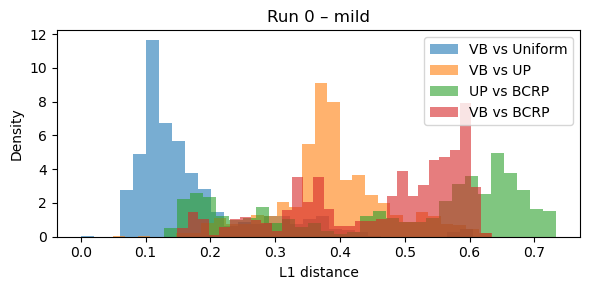

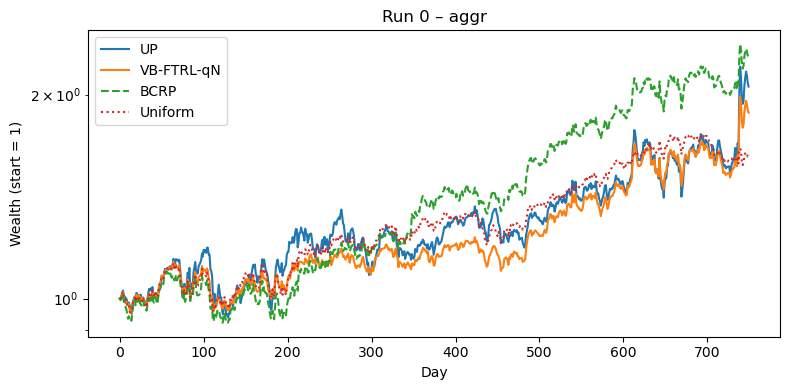

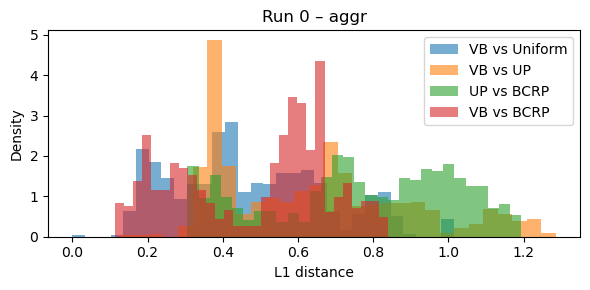

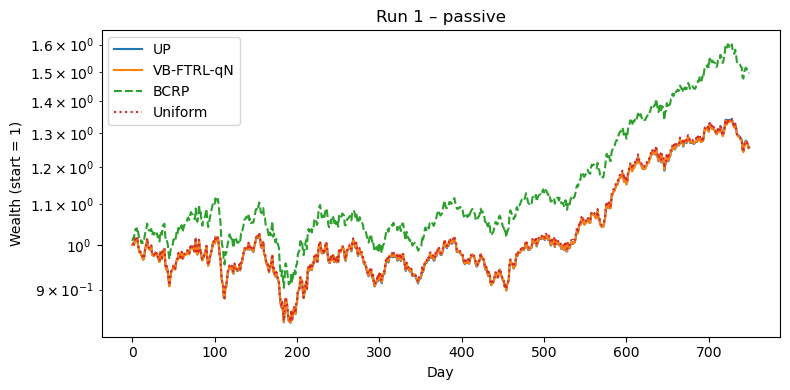

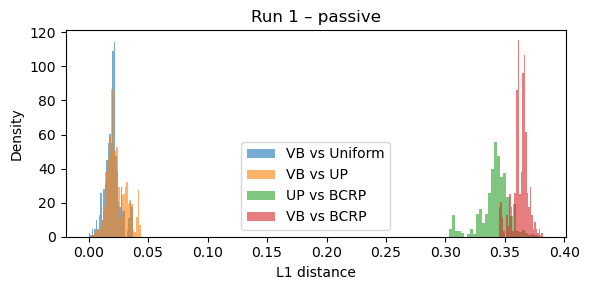

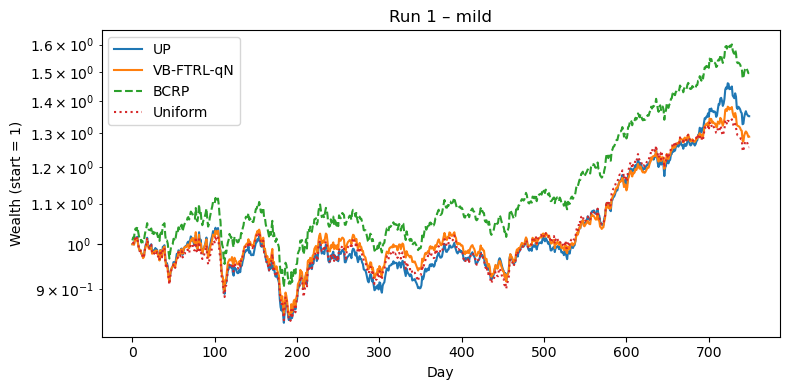

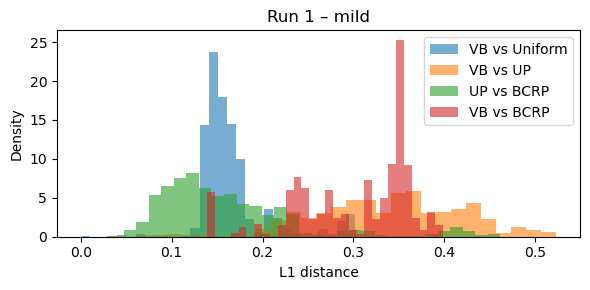

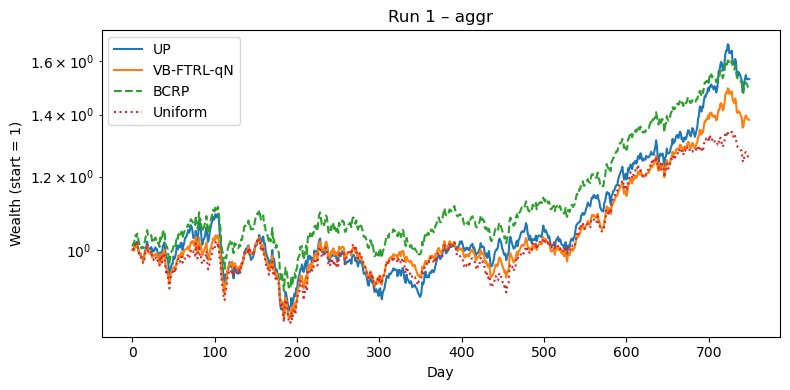

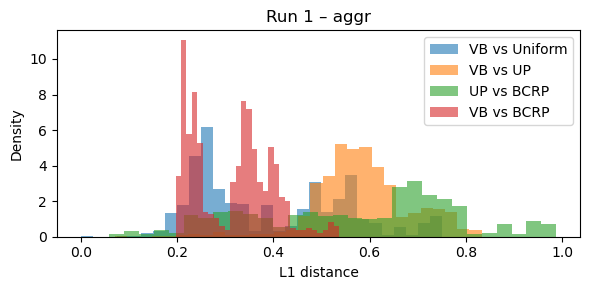

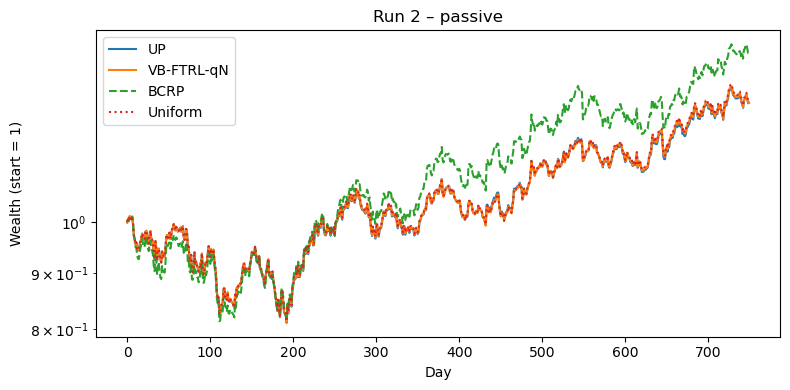

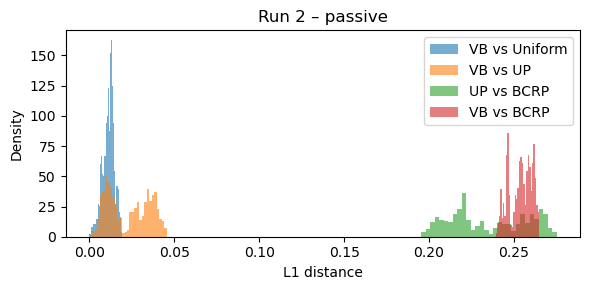

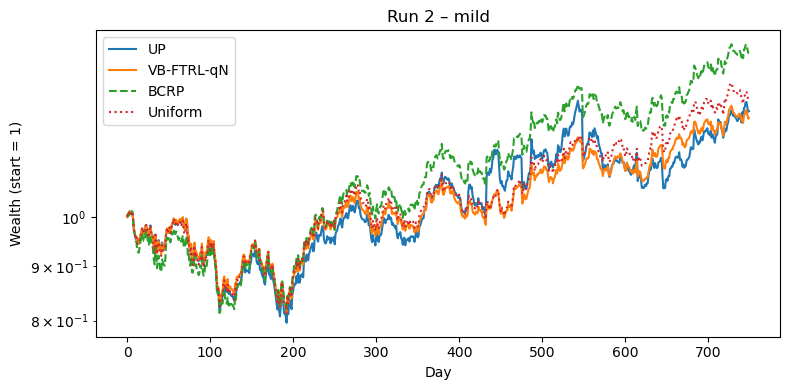

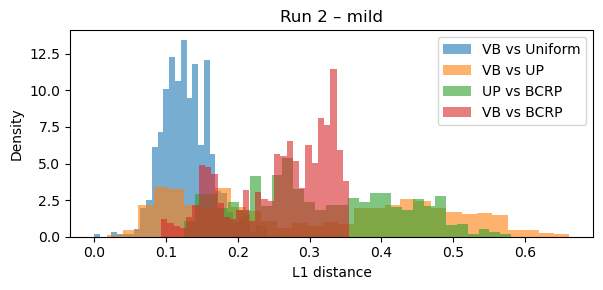

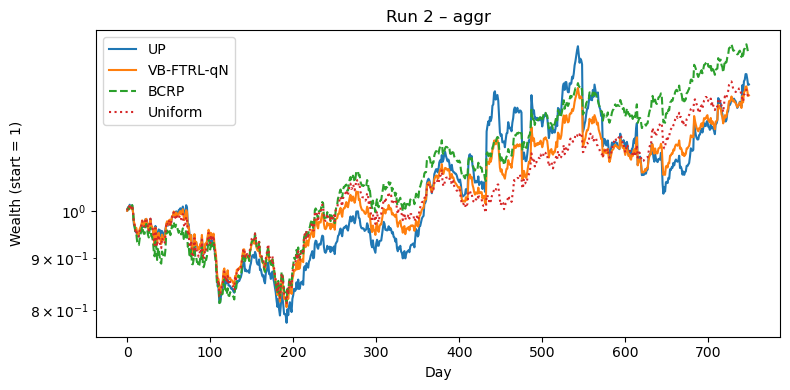

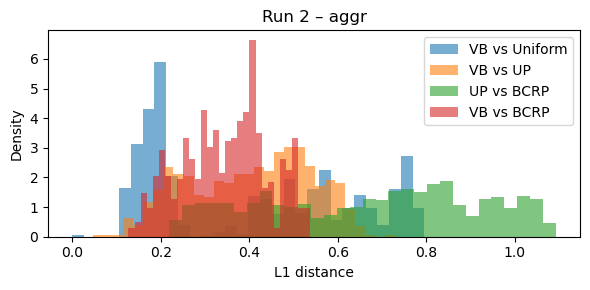

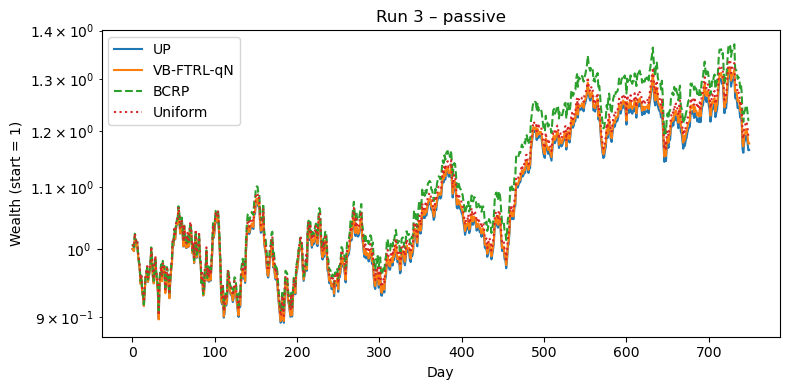

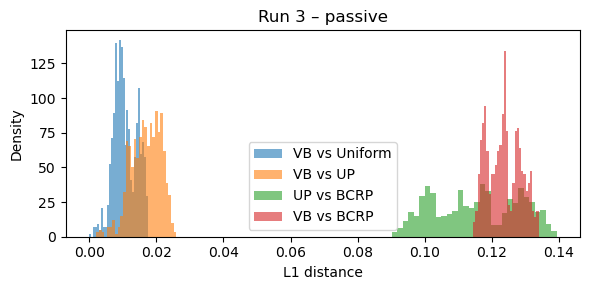

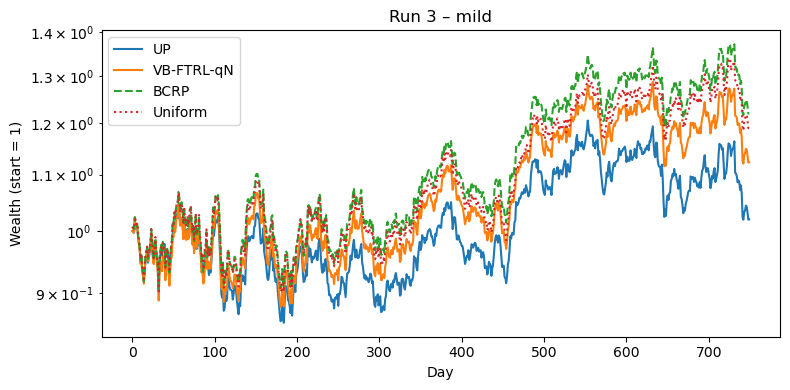

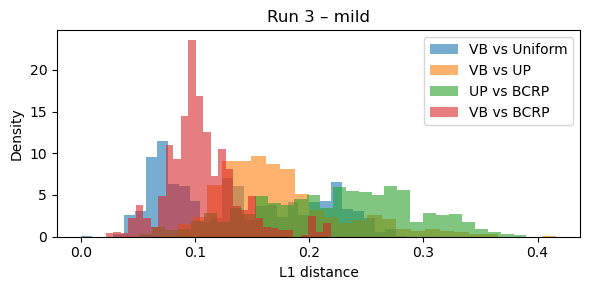

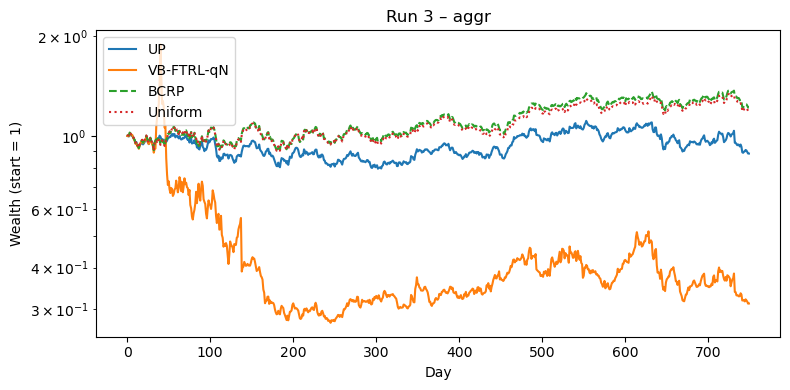

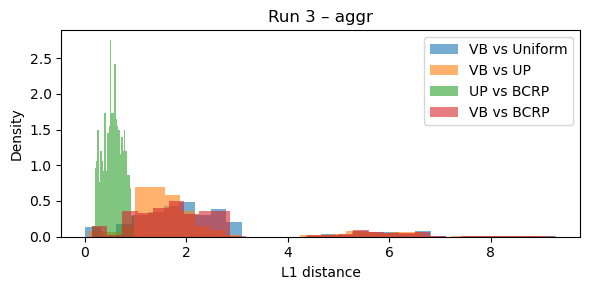

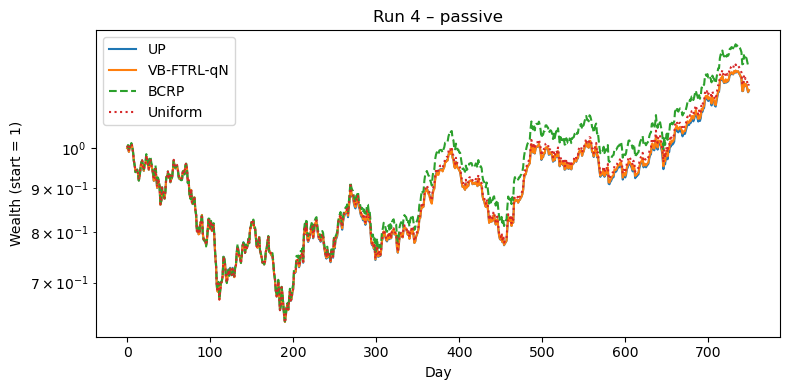

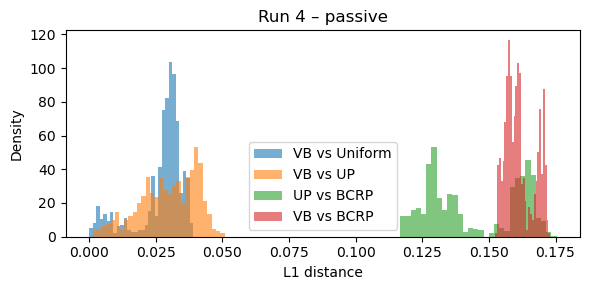

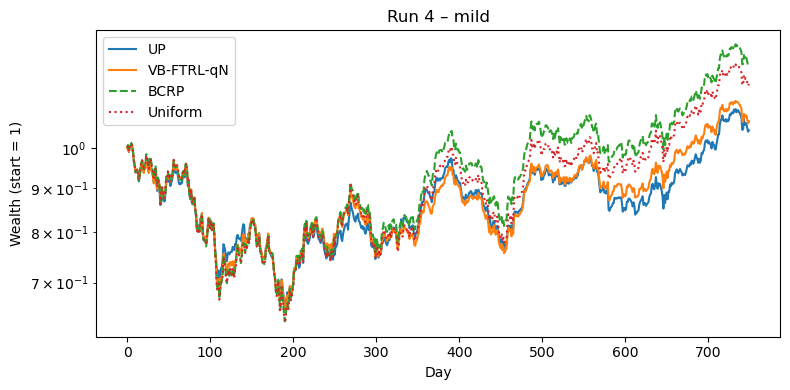

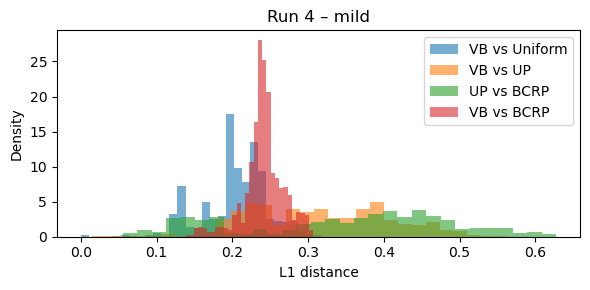

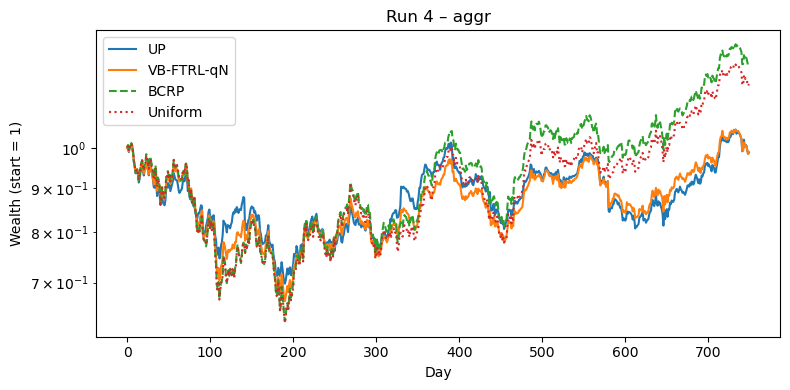

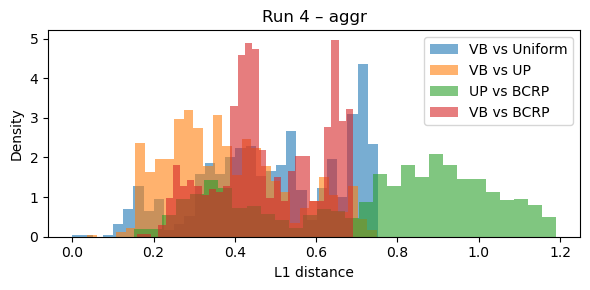

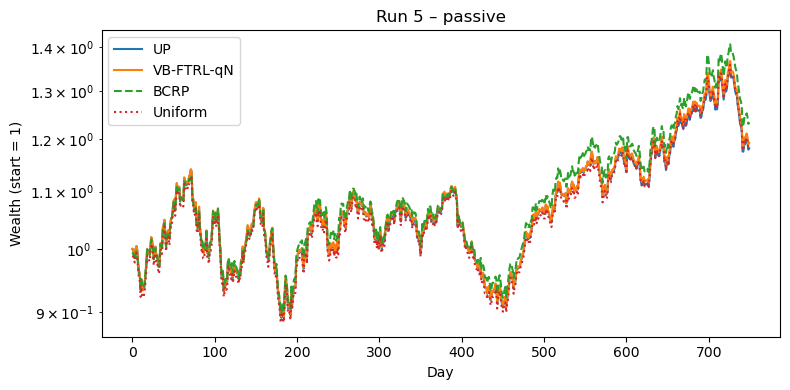

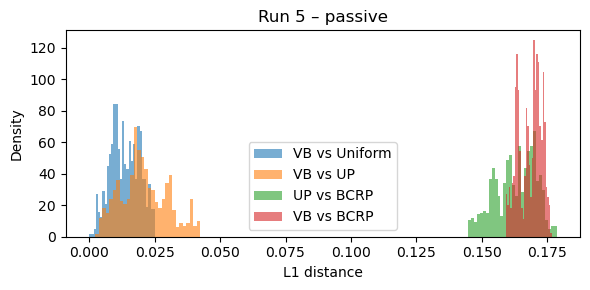

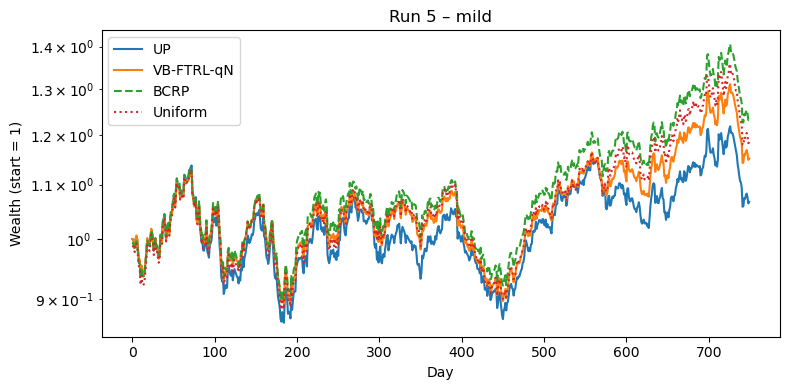

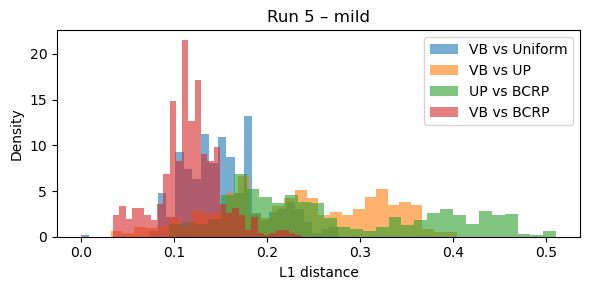

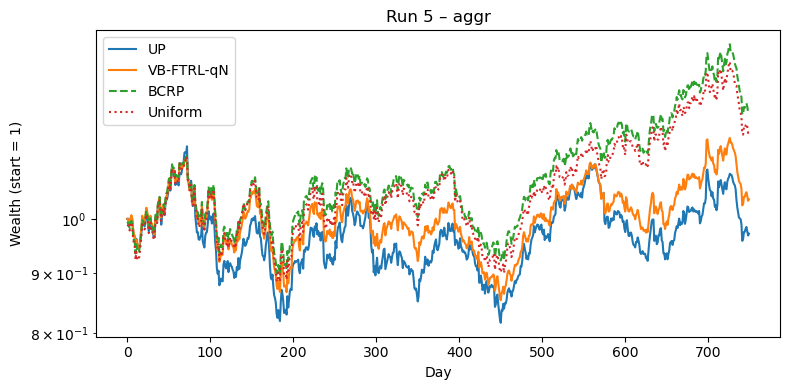

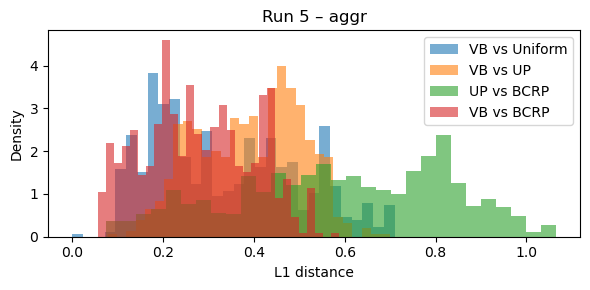

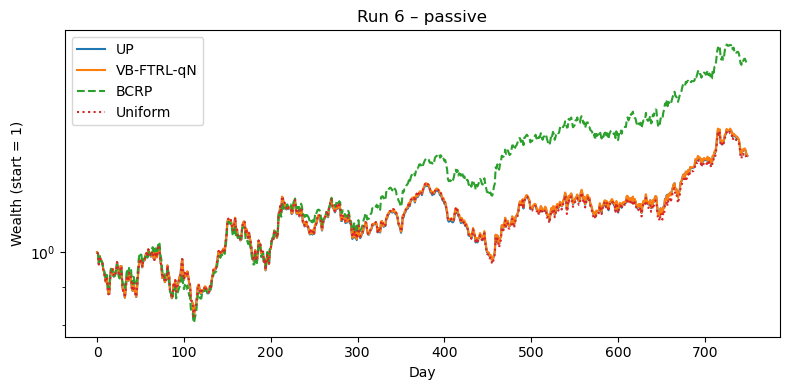

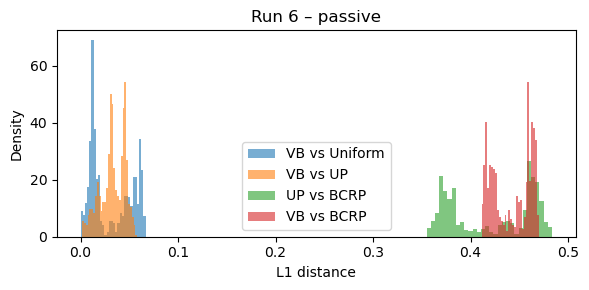

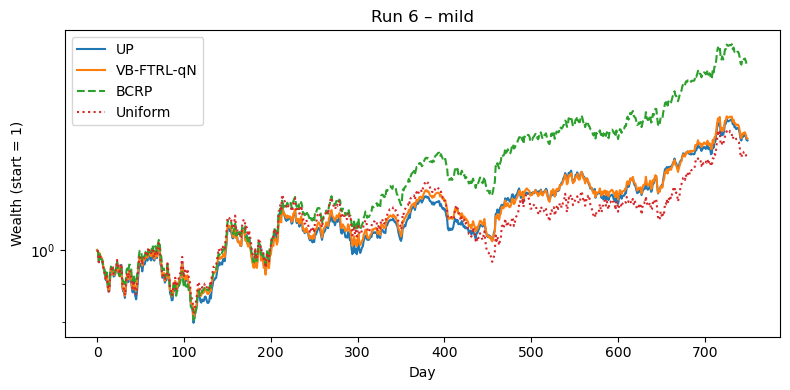

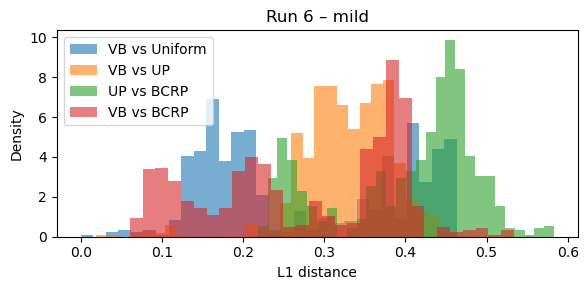

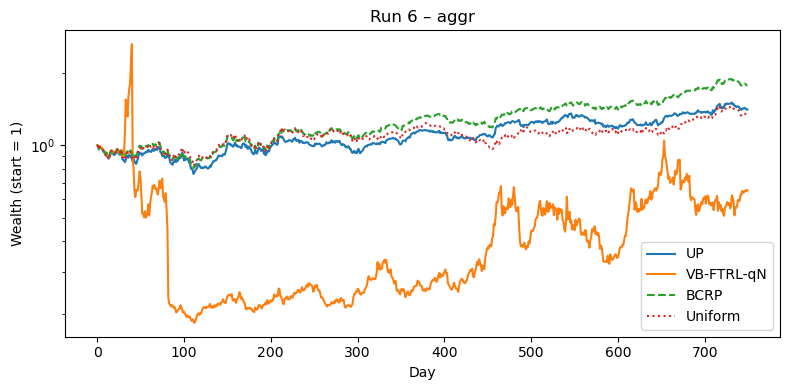

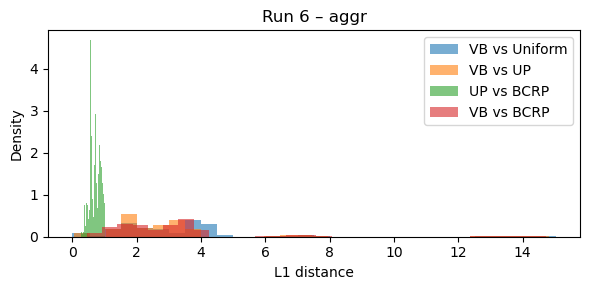

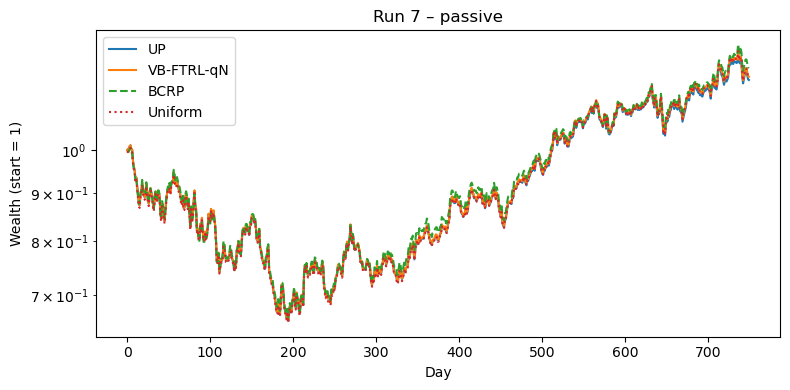

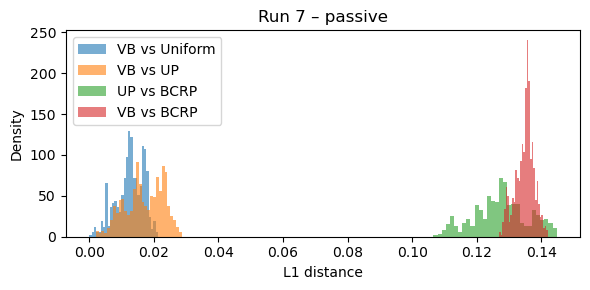

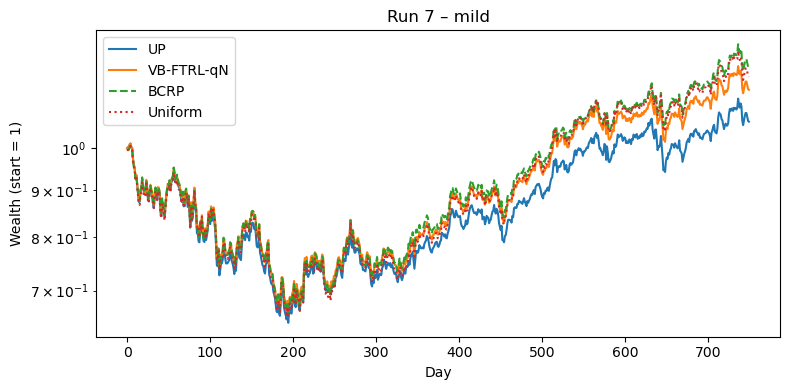

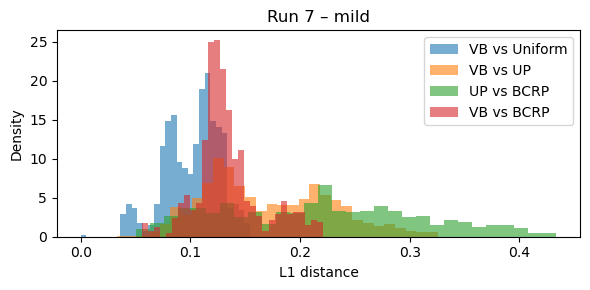

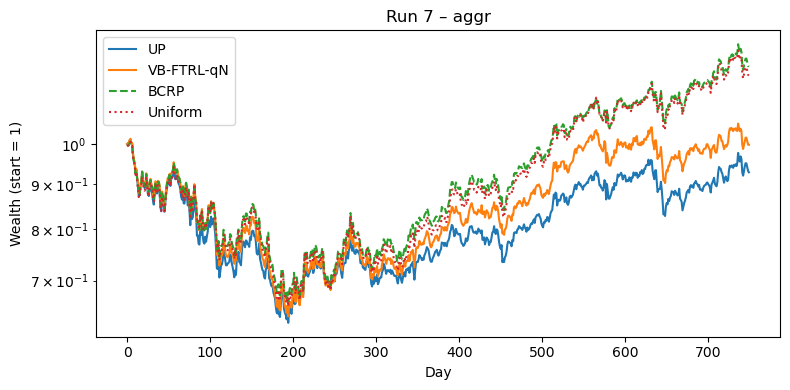

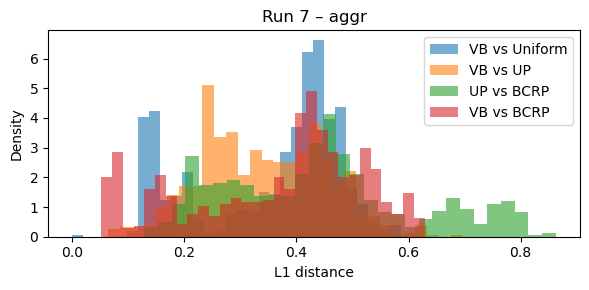

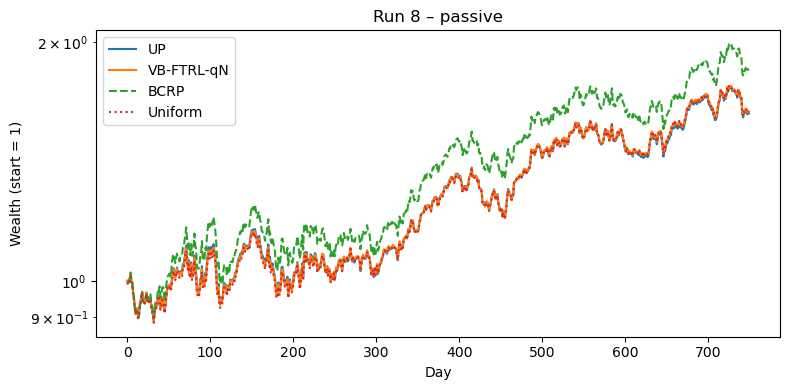

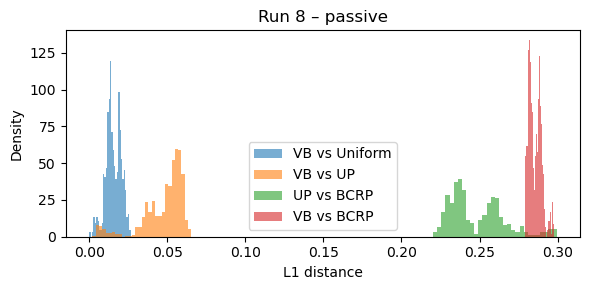

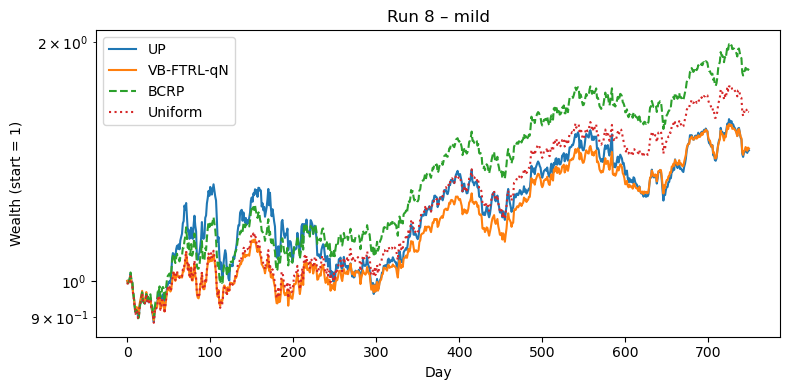

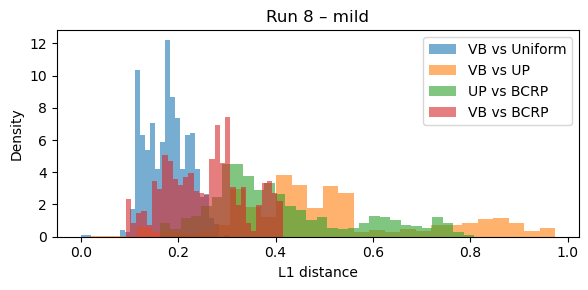

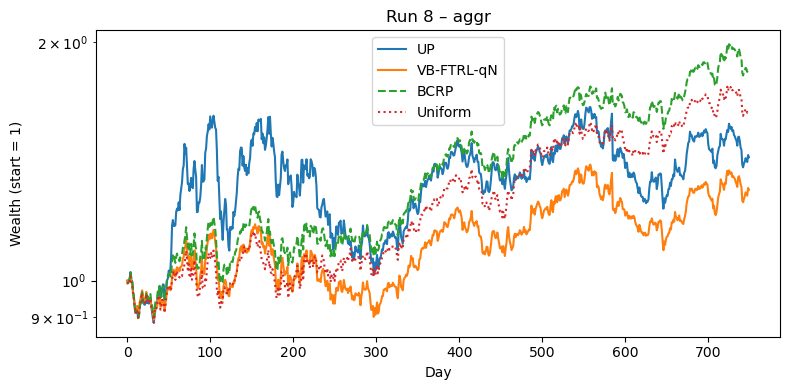

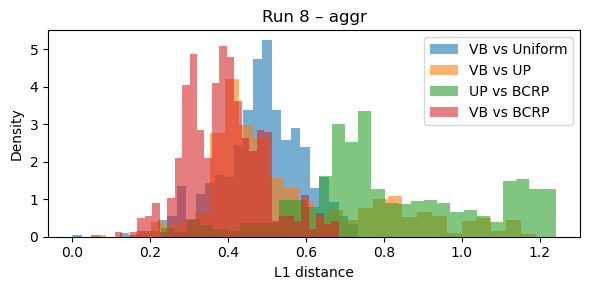

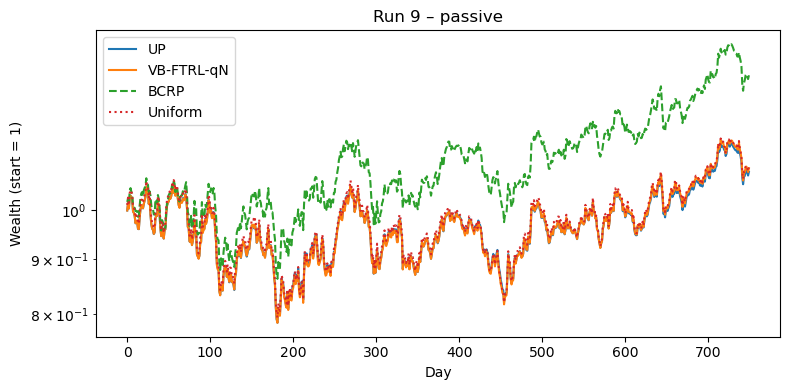

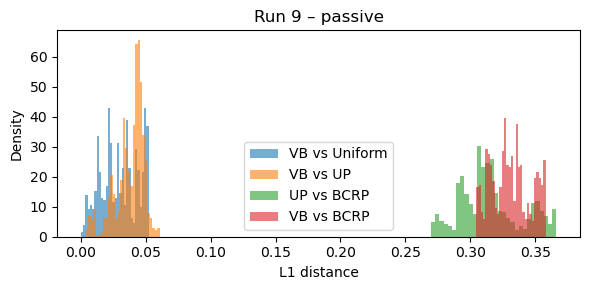

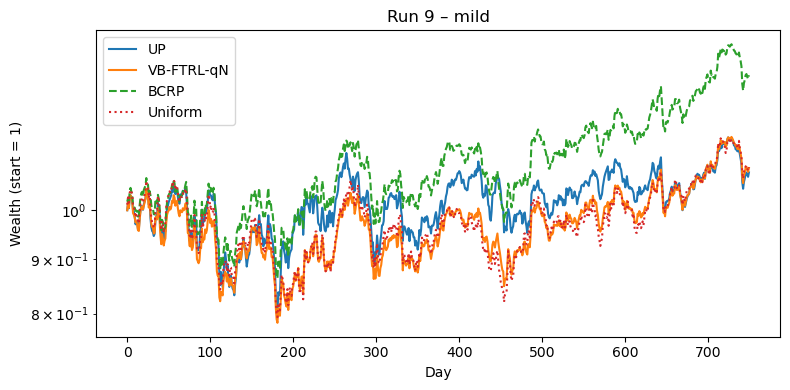

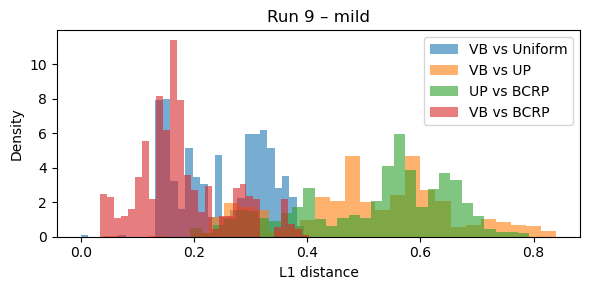

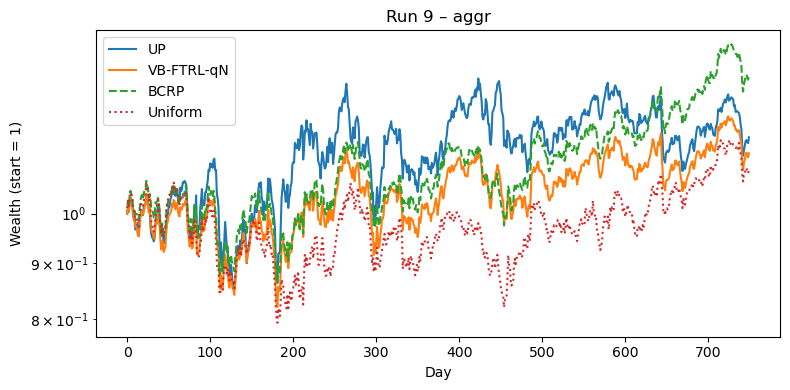

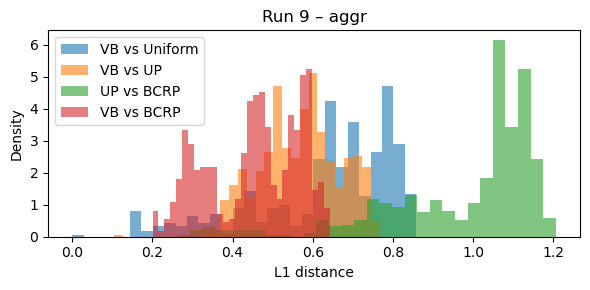

✔ Saved all per-run wealth plots + histograms in ./plots_per_run


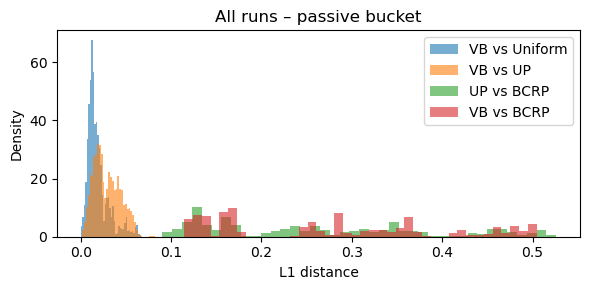

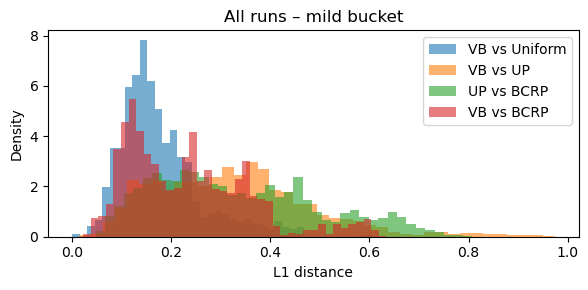

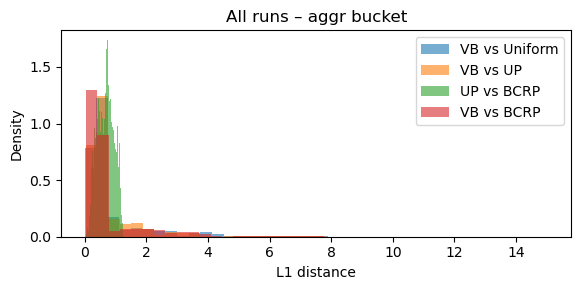

✔ Saved bucket-level aggregate histograms in ./plots_aggregate


In [ ]:
# --------------------------------------------------------------------------
# helpers (reuse if you already defined them earlier)
# --------------------------------------------------------------------------
import numpy as np, matplotlib.pyplot as plt, os

def l1_distance(W1, W2):
    return np.abs(W1 - W2).sum(axis=1)          # (T,)

def plot_wealth(rec, save_dir):
    plt.figure(figsize=(8,4))
    plt.plot(rec["S_up"],   label="UP")
    plt.plot(rec["S_vb"],   label="VB-FTRL-qN")
    plt.plot(rec["S_bcrp"], label="BCRP", linestyle="--")
    plt.plot(rec["S_uni"],  label="Uniform", linestyle=":")
    plt.yscale("log"); plt.ylabel("Wealth (start = 1)")
    plt.xlabel("Day"); plt.legend()
    title = f'Run {rec["run"]} – {rec["bucket"]}'
    plt.title(title); plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f'wealth_run{rec["run"]}_{rec["bucket"]}.png'),
                dpi=120)
    plt.show()

def plot_hist_pair(rec, save_dir):
    d_vb_up     = l1_distance(rec["W_vb"],  rec["W_up"])
    d_up_bcp    = l1_distance(rec["W_up"],  rec["w_bcrp"])
    d_vb_uni    = l1_distance(rec["W_vb"],  rec["w_uni"])
    d_bcrp_vb   = l1_distance(rec["w_bcrp"], rec["W_vb"])   # ← NEW

    plt.figure(figsize=(6,3))
    plt.hist(d_vb_uni,  bins=30, alpha=0.6, label="VB vs Uniform", density=True)
    plt.hist(d_vb_up,   bins=30, alpha=0.6, label="VB vs UP",      density=True)
    plt.hist(d_up_bcp,  bins=30, alpha=0.6, label="UP vs BCRP",    density=True)
    plt.hist(d_bcrp_vb, bins=30, alpha=0.6, label="VB vs BCRP",   density=True)  # ← NEW
    plt.xlabel("L1 distance"); plt.ylabel("Density")
    plt.title(f'Run {rec["run"]} – {rec["bucket"]}')
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(save_dir,
                f'hist_run{rec["run"]}_{rec["bucket"]}.png'), dpi=120)
    plt.show()

# --------------------------------------------------------------------------
# 1. per-run plots
# --------------------------------------------------------------------------
os.makedirs("plots_per_run_10a", exist_ok=True)

for rec in results:
    plot_wealth(rec, save_dir="plots_per_run_10a")
    plot_hist_pair(rec, save_dir="plots_per_run_10a")

print("✔ Saved all per-run wealth plots + histograms in ./plots_per_run_10a")

# --------------------------------------------------------------------------
# 2. aggregated histograms (all 10 runs) per bucket
# --------------------------------------------------------------------------
os.makedirs("plots_aggregate_10a", exist_ok=True)

for bucket in ["passive", "mild", "aggr"]:
    d_vb_uni  = np.concatenate([l1_distance(r["W_vb"], r["w_uni"])
                                for r in results if r["bucket"]==bucket])
    d_vb_up   = np.concatenate([l1_distance(r["W_vb"], r["W_up"])
                                for r in results if r["bucket"]==bucket])
    d_up_bcp  = np.concatenate([l1_distance(r["W_up"], r["w_bcrp"])
                                for r in results if r["bucket"]==bucket])
    d_bcrp_vb = np.concatenate([l1_distance(r["w_bcrp"], r["W_vb"])
                                for r in results if r["bucket"]==bucket])  # ← NEW

    plt.figure(figsize=(6,3))
    plt.hist(d_vb_uni,  bins=40, alpha=0.6, label="VB vs Uniform", density=True)
    plt.hist(d_vb_up,   bins=40, alpha=0.6, label="VB vs UP",      density=True)
    plt.hist(d_up_bcp,  bins=40, alpha=0.6, label="UP vs BCRP",    density=True)
    plt.hist(d_bcrp_vb, bins=40, alpha=0.6, label="VB vs BCRP",    density=True)  # ← NEW
    plt.xlabel("L1 distance"); plt.ylabel("Density")
    plt.title(f"All runs – {bucket} bucket"); plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join("plots_aggregate_10a",
                f'hist_aggregate_{bucket}.png'), dpi=120)
    plt.show()


print("✔ Saved bucket-level aggregate histograms in ./plots_aggregate_10a")
